# 06. Проверка надёжности выводов

Две проверки надёжности результатов:

1. **Устойчивость.** Меняются ли главные выводы, если поменять допущения очистки
   (26 рабочих дней, порог дневной ставки, границы выбросов)?
2. **Сравнение с официальной статистикой.** Правдоподобны ли зарплаты из объявлений
   на фоне данных Нацстаткома?

Ручная проверка текстовых правил (период оплаты, образование, пол) не проводилась и указана в ограничениях.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
FIG = "../reports/figures/"
K = mt.FuncFormatter(lambda x, _: f"{x/1000:.0f}k")

df = pd.read_csv("../data/processed/vacancies_clean.csv")
RATES = {"KGS": 1.0, "USD": 89.4870, "EUR": 97.7824, "RUR": 0.9785, "KZT": 0.1988}
f, t = df["compensation_from"], df["compensation_to"]
df["base"] = np.where(f.notna() & t.notna(), (f + t) / 2, f.fillna(t)) * df["compensation_currency"].map(RATES)
print(f"Объявлений с исходной зарплатой: {df['base'].notna().sum()}")

Объявлений с исходной зарплатой: 6130


## 1. Устойчивость к допущениям очистки

Функция ниже заново считает месячную зарплату при других допущениях. Классификация почасовой
и недельной оплаты остаётся прежней, меняются только параметры.

| Сценарий | Что меняется |
|---|---|
| базовый | 26 дней, дневная ставка 500–5 000, выбросы < 10 тыс. и > 600 тыс. |
| 22 / 30 дней | меньше или больше рабочих дней в месяце |
| порог 3 000 | дневной ставкой считаются только суммы 500–3 000 |
| выбросы мягче / строже | нижняя граница 8 тыс. или 12 тыс., верхняя 400 тыс. |
| без пересчитанных | все дневные, недельные и почасовые ставки исключены |

In [2]:
def make_salary(days=26, day_lo=500, day_hi=5_000, low=10_000, high=600_000, drop_converted=False):
    b = df["base"].copy()
    hour = df["pay_period"] == "hour"
    week = df["pay_period"] == "week"
    day = b.between(day_lo, day_hi, inclusive="left") & ~hour & ~week
    s = b.copy()
    s[hour] = b[hour] * 8 * days
    s[week] = b[week] * 4.33
    s[day] = b[day] * days
    if drop_converted:
        s[hour | week | day] = np.nan
    s[(s < low) | (s > high)] = np.nan
    return s

def findings(s):
    x = df.assign(s=s).dropna(subset=["s"])
    med = lambda m: x.loc[m, "s"].median()
    lal = x["source"] == "lalafo"
    return {
        "зарплат": len(x),
        "медиана рынка": x["s"].median(),
        "hh / lalafo": med(x.source == "headhunter") / med(lal),
        "опыт 3–6 / без опыта": med(x.experience == "3–6 лет") / med(x.experience == "нет опыта"),
        "Бишкек / регионы": med(x.city == "Бишкек") / med(x.city != "Бишкек"),
        "«для женщин» / остальные (lalafo)": med(lal & (x.gender_req == "женщины")) / med(lal & (x.gender_req == "не указано")),
        "самая дорогая сфера": x.groupby("category")["s"].agg(["median", "size"]).query("size >= 30")["median"].idxmax(),
    }

scen = {
    "базовый": {},
    "22 дня": {"days": 22},
    "30 дней": {"days": 30},
    "порог дневной 3 000": {"day_hi": 3_000},
    "выбросы: от 8 тыс.": {"low": 8_000},
    "выбросы: от 12 тыс.": {"low": 12_000},
    "выбросы: до 400 тыс.": {"high": 400_000},
    "без пересчитанных ставок": {"drop_converted": True},
}
rob = pd.DataFrame({k: findings(make_salary(**v)) for k, v in scen.items()}).T
rob.style.format({"медиана рынка": "{:,.0f}", "hh / lalafo": "{:.2f}", "опыт 3–6 / без опыта": "{:.2f}",
                  "Бишкек / регионы": "{:.2f}", "«для женщин» / остальные (lalafo)": "{:.2f}"})

,зарплат,медиана рынка,hh / lalafo,опыт 3–6 / без опыта,Бишкек / регионы,«для женщин» / остальные (lalafo),самая дорогая сфера
базовый,5840,"39,000",1.14,1.54,1.15,0.82,Работа за границей
22 дня,5840,"35,200",1.21,1.63,1.17,0.82,Работа за границей
30 дней,5840,"40,000",1.11,1.43,1.14,0.75,Работа за границей
порог дневной 3 000,5783,"39,000",1.14,1.60,1.15,0.85,Работа за границей
выбросы: от 8 тыс.,5863,"39,000",1.14,1.54,1.15,0.82,Работа за границей
выбросы: от 12 тыс.,5779,"39,000",1.14,1.49,1.11,0.77,Работа за границей
выбросы: до 400 тыс.,5833,"39,000",1.14,1.54,1.15,0.82,Работа за границей
без пересчитанных ставок,4742,"40,000",1.14,1.47,1.14,0.75,Работа за границей


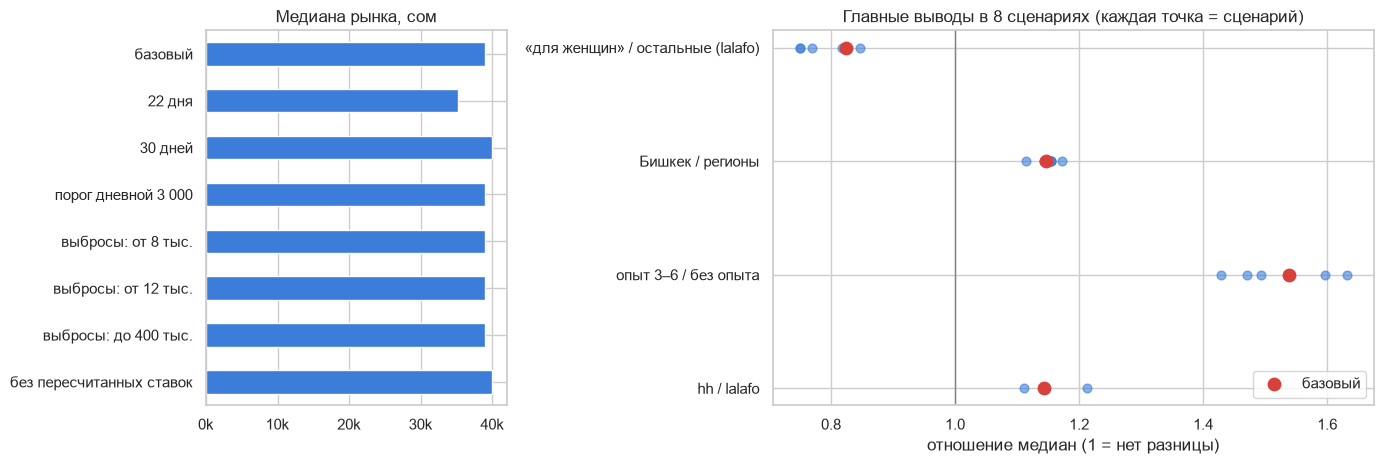

Диапазон по сценариям:
                                        min       max
hh / lalafo                            1.11      1.21
опыт 3–6 / без опыта                   1.43      1.63
Бишкек / регионы                       1.11      1.17
«для женщин» / остальные (lalafo)      0.75      0.85
медиана рынка                      35200.00  40000.00


In [3]:
num = rob.drop(columns=["самая дорогая сфера"]).astype(float)
ratios = ["hh / lalafo", "опыт 3–6 / без опыта", "Бишкек / регионы", "«для женщин» / остальные (lalafo)"]
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1, 2]})
num["медиана рынка"].plot(kind="barh", ax=ax[0], color="#3b7dd8")
ax[0].xaxis.set_major_formatter(K); ax[0].set_title("Медиана рынка, сом"); ax[0].invert_yaxis()
for i, c in enumerate(ratios):
    ax[1].scatter(num[c], [i] * len(num), color="#3b7dd8", alpha=.6, s=40)
    ax[1].scatter(num.loc["базовый", c], i, color="#d8403b", s=80, zorder=3, label="базовый" if i == 0 else None)
ax[1].axvline(1, color="grey", lw=1)
ax[1].set_yticks(range(len(ratios))); ax[1].set_yticklabels(ratios)
ax[1].set_xlabel("отношение медиан (1 = нет разницы)"); ax[1].legend(loc="lower right")
ax[1].set_title("Главные выводы в 8 сценариях (каждая точка = сценарий)")
plt.tight_layout(); plt.savefig(FIG + "06_robustness.png", dpi=150); plt.show()

print("Диапазон по сценариям:")
print(num[ratios + ["медиана рынка"]].agg(["min", "max"]).T.round(2))

**Вывод по устойчивости:** все главные выводы сохраняют направление во всех 8 сценариях.

| Вывод | Базовый | Диапазон по сценариям |
|---|---|---|
| hh платит больше lalafo | ×1,14 | ×1,11 … ×1,21 |
| опыт 3–6 лет против «без опыта» | ×1,54 | ×1,43 … ×1,63 |
| Бишкек против регионов | ×1,15 | ×1,11 … ×1,17 |
| «для женщин» против остальных (lalafo) | ×0,82 | ×0,75 … ×0,85 |
| самая дорогая сфера | работа за границей | та же во всех сценариях |

Сильнее всего от допущений зависит **медиана рынка**: 35 200 сом при 22 рабочих днях и 39 000–40 000
во всех остальных сценариях. Поэтому точное значение медианы лучше подавать как «около 35–40 тыс. сом»,
а сравнения между группами можно считать надёжными.

## 2. Сравнение с официальной статистикой

Официальные данные Нацстаткома (через economist.kg):

| Показатель | Значение | Период | Источник |
|---|---|---|---|
| Средняя зарплата по стране | 34 046 сом | январь–март 2024 | [economist.kg, 14.05.2024](https://economist.kg/dengi/2024/05/14/za-ghod-zarplaty-v-kr-vyrosli-na-3-4-tysiachi-somov/) |
| Средняя зарплата, Бишкек | 43 782 сом | январь–сентябрь 2024 | [economist.kg, 27.11.2024](https://economist.kg/dengi/2024/11/27/bishkiek-i-issyk-kulskaia-oblast-lidiruiut-po-urovniu-sriednikh-zarplat-v-kyrghyzstanie/) |
| Средняя зарплата, г. Ош | 29 882 сом | январь–сентябрь 2024 | там же |

**Важно для сравнения:**
- официальная цифра это **среднее** (не медиана) по **работающим** людям, включая госсектор;
  в объявлениях только **предложения** новым сотрудникам, в основном частный сектор;
- официальные данные не включают малые предприятия;
- региональные цифры за январь–сентябрь, а зарплаты за год выросли примерно на 11%,
  поэтому для февраля–марта они немного завышены.

In [4]:
sal = df[df["has_salary"]]
bench = pd.DataFrame({
    "официально (среднее)": {"Кыргызстан": 34_046, "Бишкек": 43_782, "г. Ош": 29_882},
    "объявления: среднее": {"Кыргызстан": sal["salary_kgs"].mean(),
                            "Бишкек": sal.loc[sal.area == "Бишкек", "salary_kgs"].mean(),
                            "г. Ош": sal.loc[sal.area == "Ош", "salary_kgs"].mean()},
    "объявления: медиана": {"Кыргызстан": sal["salary_kgs"].median(),
                            "Бишкек": sal.loc[sal.area == "Бишкек", "salary_kgs"].median(),
                            "г. Ош": sal.loc[sal.area == "Ош", "salary_kgs"].median()},
    "n объявлений": {"Кыргызстан": len(sal), "Бишкек": (sal.area == "Бишкек").sum(), "г. Ош": (sal.area == "Ош").sum()},
})
bench["среднее объявлений / официальное"] = bench["объявления: среднее"] / bench["официально (среднее)"]
bench.style.format({"официально (среднее)": "{:,.0f}", "объявления: среднее": "{:,.0f}",
                    "объявления: медиана": "{:,.0f}", "n объявлений": "{:,.0f}",
                    "среднее объявлений / официальное": "{:.2f}"})

,официально (среднее),объявления: среднее,объявления: медиана,n объявлений,среднее объявлений / официальное
Кыргызстан,"34,046","47,796","39,000","5,840",1.40
Бишкек,"43,782","48,092","39,000","5,051",1.10
г. Ош,"29,882","49,248","37,500",111,1.65


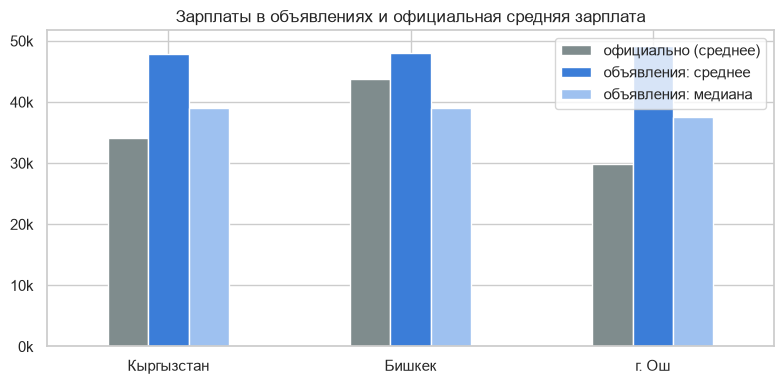

In [5]:
ax = bench[["официально (среднее)", "объявления: среднее", "объявления: медиана"]].plot(
    kind="bar", figsize=(8, 4), color=["#7f8c8d", "#3b7dd8", "#9ec1f0"])
ax.yaxis.set_major_formatter(K); ax.set_xlabel(""); plt.xticks(rotation=0); ax.legend(title="")
ax.set_title("Зарплаты в объявлениях и официальная средняя зарплата")
plt.tight_layout(); plt.savefig(FIG + "06_benchmark.png", dpi=150); plt.show()

**Вывод:** медиана объявлений по стране (39 000) немного выше официальной средней (34 046), а среднее
объявлений (≈ 47 800) выше примерно на 40%. Для Бишкека разница меньше: среднее в объявлениях
≈ 48 100 против официальных 43 782 (+10%). Разрыв по стране в основном объясняется тем,
что 83% объявлений из Бишкека, где зарплаты выше.

**Итог:** порядок цифр совпадает с официальной статистикой, значит, очистка не исказила зарплаты.
Объявления систематически выше официальных данных, что ожидаемо: это предложения частного сектора,
в основном столичного. По г. Ош (111 объявлений) расхождение больше, и выводы по региону ненадёжны.

## Итоги проверки

- **Устойчивость:** все главные сравнения сохраняют направление в 8 сценариях; медиана рынка
  колеблется от 35 до 40 тыс. сом в зависимости от числа рабочих дней.
- **Официальная статистика:** в Бишкеке среднее в объявлениях всего на 10% выше официального,
  по стране на 40% (из-за перевеса Бишкека в объявлениях). Порядок цифр совпадает.
- **Ограничение:** текстовые правила вручную не проверялись. Устойчивость выводов к допущениям
  частично компенсирует это: главные сравнения не меняют направления.